# 🔬 Análisis Exhaustivo de Falsos Positivos (FP) sobre Noticias Útiles (`is_ruido == False`)

Este notebook realiza la **auditoría programática completa y depuración** sobre las **37,359 noticias clasificadas como útiles (`is_ruido == False`)** en el periodo **2010–2023**:
- **Ruta compartida en Cloudflare R2 (Equipo TFM):** `tfm-master-prediccion-bancos-usa/processed/huggingface/df_util/df_util_2010_2023.parquet`.
- **Universo de estudio:** Los 6 grandes bancos de EE. UU. (**US Big 6**: `BAC`, `C`, `GS`, `JPM`, `MS`, `WFC`).

### Estructura del Análisis:
1. **Bloque 1 — Sincronización y Carga de `df_util` desde Cloudflare R2:** Lee directamente desde `processed/huggingface/df_util` (y si aún no existe en R2 en la primera ejecución, lo genera y publica automáticamente para que quede disponible para todo el equipo).
2. **Bloque 2 — Diagnóstico de Presencia de la Entidad Bancaria (`Titular` vs. `Fragmento`):** Evalúa en cuántas noticias útiles aparece realmente el nombre/alias del banco.
3. **Bloque 3 — Taxonomía de las 5 Cubetas de Falsos Positivos (`FP_1` a `FP_5`) vs. Núcleo Limpio (`TP`):** Clasifica las 37,359 noticias según las 5 puertas traseras detectadas en la auditoría cualitativa.
4. **Bloque 4 — Inspección Muestral por Cubeta de FP:** Muestra ejemplos aleatorios de cada cubeta de error para validar que no se descartan noticias legítimas.
5. **Bloque 5 — Impacto en la Cobertura Temporal Anual (2010–2023):** Compara los mapas de calor Antes vs. Después de limpiar los Falsos Positivos.
6. **Bloque 6 — Validación Final de Pureza sobre el Núcleo Limpio:** Extrae 5 noticias aleatorias por banco tras la limpieza para verificar la mejora en precisión.

---
## 1. Sincronización y Carga de `df_util` (`is_ruido == False`) en Cloudflare R2

En esta celda conectamos con el bucket `tfm-master-prediccion-bancos-usa` en Cloudflare R2:
* Si el archivo `processed/huggingface/df_util/df_util_2010_2023.parquet` **ya existe en R2**, lo descarga directamente en un par de segundos.
* Si es la **primera ejecución** y aún no se ha subido a `processed/huggingface/df_util`, lo filtra automáticamente a partir del dataset Silver (`is_ruido == False`, `2010–2023`) y **lo sube a R2** para que quede compartido para todo el equipo del Máster.

In [1]:
import sys
import re
from pathlib import Path
import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.fs as fs
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Resolver ruta hacia 'src' para importar la configuración y diccionarios del proyecto
CURRENT_DIR = Path.cwd().resolve()
SRC_PATH = str(CURRENT_DIR.parent) if CURRENT_DIR.name == "notebooks" else str(CURRENT_DIR / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from config.settings import settings
from shared.tickets import ALIAS_BANCOS, ANALYST_ROLE_TERMS, MACRO_KEYWORDS

# Configurar el sistema de archivos S3/R2
s3_fs = fs.S3FileSystem(
    access_key=settings.aws_access_key_id,
    secret_key=settings.aws_secret_access_key,
    endpoint_override=settings.s3_endpoint_url,
    region=settings.s3_region
)

R2_UTIL_PATH = f"{settings.s3_bucket_name}/processed/huggingface/df_util/df_util_2010_2023.parquet"
R2_SILVER_PATH = f"{settings.s3_bucket_name}/processed/huggingface/multisource_bancos_2010_2023.parquet"

def cargar_o_publicar_df_util() -> pd.DataFrame:
    """Carga df_util desde R2 (processed/huggingface/df_util) o lo crea y sube si aún no existe."""
    info = s3_fs.get_file_info(R2_UTIL_PATH)
    if info.type == fs.FileType.File:
        print(f"✔ Cargando df_util directamente desde R2: [{R2_UTIL_PATH}] ({info.size / (1024*1024):.2f} MB)...")
        return pq.read_table(R2_UTIL_PATH, filesystem=s3_fs).to_pandas()

    print(f"Archivo aún no encontrado en [{R2_UTIL_PATH}]. Generando desde Silver y subiendo a R2...")
    df_full = pq.read_table(R2_SILVER_PATH, filesystem=s3_fs).to_pandas()
    df_full["datetime"] = pd.to_datetime(df_full["datetime"], errors="coerce", utc=True)
    df_full["year"] = df_full["datetime"].dt.year
    df_u = df_full[(df_full["year"] >= 2010) & (df_full["year"] <= 2023) & (~df_full["is_ruido"])].copy()

    # Subir a Cloudflare R2 en processed/huggingface/df_util
    tabla_u = pa.Table.from_pandas(df_u, preserve_index=False)
    pq.write_table(tabla_u, R2_UTIL_PATH, filesystem=s3_fs, compression="zstd")
    info_new = s3_fs.get_file_info(R2_UTIL_PATH)
    print(f"✔ df_util publicado exitosamente en R2: [{R2_UTIL_PATH}] ({info_new.size / (1024*1024):.2f} MB).")
    return df_u

df_util = cargar_o_publicar_df_util()
print(f"Total noticias útiles cargadas (is_ruido == False): {len(df_util):,} registros x {df_util.shape[1]} columnas.")
display(df_util.head())

Archivo aún no encontrado en [tfm-master-prediccion-bancos-usa/processed/huggingface/df_util/df_util_2010_2023.parquet]. Generando desde Silver y subiendo a R2...
✔ df_util publicado exitosamente en R2: [tfm-master-prediccion-bancos-usa/processed/huggingface/df_util/df_util_2010_2023.parquet] (19.83 MB).
Total noticias útiles cargadas (is_ruido == False): 37,359 registros x 14 columnas.


,ticker,company_name,cik,date,datetime,title,article,ticker_count,is_multisubject,process_text,category,confianza,is_ruido,year
7,GS,Goldman Sachs Group Inc.,CIK0000886982,2010-01-04 16:44:00,2010-01-04 16:44:00+00:00,Bernanke's No Inflation Hawk; Buy Bonds,Regarding the note earlier that Ben Bernanke a...,5,True,Regarding the note earlier that Ben Bernanke a...,macro,60.1,False,2010
8,BAC,Bank of America Corp /DE/,CIK0000070858,2010-01-04 16:44:00,2010-01-04 16:44:00+00:00,Bernanke's No Inflation Hawk; Buy Bonds,Regarding the note earlier that Ben Bernanke a...,5,True,Regarding the note earlier that Ben Bernanke a...,macro,60.1,False,2010
9,JPM,JPMorgan Chase & Co.,CIK0000019617,2010-01-04 16:44:00,2010-01-04 16:44:00+00:00,Bernanke's No Inflation Hawk; Buy Bonds,Regarding the note earlier that Ben Bernanke a...,5,True,Regarding the note earlier that Ben Bernanke a...,macro,60.1,False,2010
10,MS,Morgan Stanley,CIK0000895421,2010-01-04 16:44:00,2010-01-04 16:44:00+00:00,Bernanke's No Inflation Hawk; Buy Bonds,Regarding the note earlier that Ben Bernanke a...,5,True,Regarding the note earlier that Ben Bernanke a...,macro,60.1,False,2010
11,WFC,Wells Fargo & Company/MN,CIK0000072971,2010-01-04 16:44:00,2010-01-04 16:44:00+00:00,Bernanke's No Inflation Hawk; Buy Bonds,Regarding the note earlier that Ben Bernanke a...,5,True,Regarding the note earlier that Ben Bernanke a...,macro,60.1,False,2010


---
## 2. Radiografía de Presencia de la Entidad Bancaria (`Titular` vs. `Fragmento`)

Antes de clasificar los Falsos Positivos, evaluamos en cuántas de las **37,359 noticias útiles** aparece realmente el nombre o alias oficial del banco asignado en `ticker`:
1. **`banco_en_title`:** ¿El titular (`title`) menciona explícitamente al banco?
2. **`banco_en_ctx`:** ¿El fragmento procesado (`process_text`) menciona explícitamente al banco?
3. **`sin_cuerpo`:** ¿El registro carece de cuerpo extraído (`process_text == '(Titular directo sin cuerpo)'`)?

In [2]:
# Patrones regex por banco basados en shared/tickets.py + nombres históricos de CEOs/entidades
PATRONES_BANCOS = {
    "JPM": r"\b(JPM|JPMorgan|J\.P\. Morgan|JP Morgan|Chase|Dimon)\b",
    "BAC": r"\b(BAC|Bank of America|B of A|BofA|Merrill|Moynihan)\b",
    "C":   r"\b(Citigroup|Citi|Citibank|Fraser|Corbat|Pandit)\b|\(\s*C\s*\)|NYSE:\s*C\b",
    "WFC": r"\b(WFC|Wells Fargo|Wells|Scharf|Stumpf|Sloan)\b",
    "GS":  r"\b(GS|Goldman|Goldman Sachs|Solomon|Blankfein)\b",
    "MS":  r"\b(MS|Morgan Stanley|Gorman|Ted Pick)\b",
}

TAG_SIN_CUERPO = "(Titular directo sin cuerpo)"
df_util["sin_cuerpo"] = df_util["process_text"] == TAG_SIN_CUERPO

# Evaluar presencia del propio banco en titular y en fragmento
df_util["banco_en_title"] = [
    bool(re.search(PATRONES_BANCOS[t], str(ti), re.IGNORECASE))
    for t, ti in zip(df_util["ticker"], df_util["title"])
]
df_util["banco_en_ctx"] = [
    False if sc else bool(re.search(PATRONES_BANCOS[t], str(ct), re.IGNORECASE))
    for t, ct, sc in zip(df_util["ticker"], df_util["process_text"], df_util["sin_cuerpo"])
]

# Clasificar el tipo de anclaje de la entidad en 4 cuadrantes
condiciones_anclaje = [
    df_util["banco_en_title"] & df_util["banco_en_ctx"],
    df_util["banco_en_title"] & df_util["sin_cuerpo"],
    df_util["banco_en_title"] & (~df_util["sin_cuerpo"]) & (~df_util["banco_en_ctx"]),
    (~df_util["banco_en_title"]) & df_util["banco_en_ctx"],
    (~df_util["banco_en_title"]) & (~df_util["banco_en_ctx"]) & df_util["sin_cuerpo"],
    (~df_util["banco_en_title"]) & (~df_util["banco_en_ctx"]) & (~df_util["sin_cuerpo"]),
]
etiquetas_anclaje = [
    "1. Anclaje Doble (Banco en Titular y Cuerpo)",
    "2. Titular Flash Válido (Banco en Titular, Sin Cuerpo)",
    "3. Banco en Titular, Cuerpo Fallback",
    "4. Solo en Cuerpo (Titular NO menciona al banco)",
    "5. Huérfano Sin Cuerpo (NI en Titular NI Cuerpo) [FP]",
    "6. Fallback Sin Banco (Con Cuerpo, pero NI en Titular NI Cuerpo) [FP]",
]
df_util["tipo_anclaje"] = np.select(condiciones_anclaje, etiquetas_anclaje, default="Otro")

resumen_anclaje = (
    df_util["tipo_anclaje"]
    .value_counts()
    .rename_axis("Tipo de Anclaje de Entidad")
    .reset_index(name="Noticias")
)
resumen_anclaje["% sobre Útiles (37,359)"] = (resumen_anclaje["Noticias"] / len(df_util) * 100).round(2)

print("=" * 95)
print("DIAGNÓSTICO DE PRESENCIA DEL BANCO EN NOTICIAS ÚTILES (is_ruido == False)")
print("=" * 95)
display(resumen_anclaje)

DIAGNÓSTICO DE PRESENCIA DEL BANCO EN NOTICIAS ÚTILES (is_ruido == False)


,Tipo de Anclaje de Entidad,Noticias,"% sobre Útiles (37,359)"
0,4. Solo en Cuerpo (Titular NO menciona al banco),14217,38.06
1,1. Anclaje Doble (Banco en Titular y Cuerpo),7756,20.76
2,"2. Titular Flash Válido (Banco en Titular, Sin...",7085,18.96
3,"6. Fallback Sin Banco (Con Cuerpo, pero NI en ...",3935,10.53
4,5. Huérfano Sin Cuerpo (NI en Titular NI Cuerp...,3518,9.42
5,"3. Banco en Titular, Cuerpo Fallback",848,2.27


---
## 3. Taxonomía Exhaustiva de Falsos Positivos: Las 5 Cubetas de Error vs. Núcleo Limpio (`TP`)

Aplicamos de forma jerárquica y mutuamente excluyente las **5 reglas de detección de Falsos Positivos** documentadas en `FP_origen_auditoria_zero_shot.md`:
1. **`FP_1_Huerfano_Sin_Cuerpo`:** `process_text == '(Titular directo sin cuerpo)'` y el titular no menciona ni al banco ni términos colectivos de banca (`banks`, `banking`, `financials`, `stress test`).
2. **`FP_2_Fallback_Sin_Banco`:** Tiene texto en `process_text`, pero **ni el titular ni el fragmento mencionan al banco** y el titular tampoco habla explícitamente del sector bancario.
3. **`FP_3_Cross_Bank_Bleed`:** El titular menciona explícitamente a **otro banco competidor** del *Big 6*, **no** menciona al banco del `ticker` (ni habla de `banks` en plural) y el fragmento no contiene comparativas conjuntas.
4. **`FP_4_Rol_Analista_Pronostico`:** El titular no menciona al banco (habla de otra empresa) y el fragmento presenta jerga de analista/recomendación (`downgrade/upgrade from`, `price target`, `analyst`, `maintains`, `initiates`), o el banco solo emite un pronóstico macroeconómico general (`cuts/raises forecast for GDP/inflation/oil`).
5. **`FP_5_Plantilla_13F_ETF_TV`:** Notas robotizadas de carteras de fondos (`% of the total portfolio`, `ETF Inflow Alert`) o listas televisivas multi-sector sin cuerpo (`Fast Money Picks`, `Stocks in focus`).
6. **`TP_Nucleo_Limpio`:** Noticias que superan los 5 filtros y constituyen la señal financiera depurada.

In [3]:
# Términos explícitos del sector bancario que justifican una noticia sistémica aunque no nombre al ticker en el titular
PATRON_SECTOR_BANCARIO = r"\b(banks?|banking|big banks|wall street banks|financial stocks|financials|stress tests?|ccar|fdic|bank reg|dodd-frank)\b"

# Patrones ampliados de rol de analista sobre terceros y pronósticos macro de casa de estudios
PATRON_ANALISTA_AMPLIADO = (
    r"\b(upgrades?|downgrades?|upgraded|downgraded|initiates?|reiterates?|maintains?|"
    r"price target|target price|cut to|raised to|analyst|analysts|strategist|strategists|"
    r"economist|economists|note to clients|equity research|top picks?|estimates?)\b"
)
PATRON_PRONOSTICO_CASA = r"\b(cuts? forecast|raises? forecast|cuts? target|gdp forecast|economic growth target|warns bond traders)\b"

# Patrones de plantillas robotizadas 13F / ETFs y listas de TV sin cuerpo
PATRON_13F_ETF = r"(% of the total portfolio|shares,\s*\d+\.\d+% of|etf inflow alert|etf outflow alert|13f|holdings page)"
PATRON_LISTA_TV = r"(fast money picks|final trade|stocks in focus|stocks to watch)"

# Precalcular señales auxiliares vectorizadas
t_str = df_util["title"].astype(str)
c_str = df_util["process_text"].astype(str)

df_util["sector_bancario_en_title"] = t_str.str.contains(PATRON_SECTOR_BANCARIO, case=False, regex=True)
df_util["jerga_analista"] = c_str.str.contains(PATRON_ANALISTA_AMPLIADO, case=False, regex=True)
df_util["pronostico_casa"] = t_str.str.contains(PATRON_PRONOSTICO_CASA, case=False, regex=True) | c_str.str.contains(PATRON_PRONOSTICO_CASA, case=False, regex=True)
df_util["es_plantilla_13f"] = t_str.str.contains(PATRON_13F_ETF, case=False, regex=True) | c_str.str.contains(PATRON_13F_ETF, case=False, regex=True)
df_util["es_lista_tv"] = t_str.str.contains(PATRON_LISTA_TV, case=False, regex=True) & df_util["sin_cuerpo"]

# Detectar si el titular menciona a OTRO banco competidor pero NO al banco del ticker
def menciona_otro_banco_en_title(row_ticker: str, title_text: str) -> bool:
    for otro_tk, pat in PATRONES_BANCOS.items():
        if otro_tk != row_ticker and re.search(pat, title_text, re.IGNORECASE):
            return True
    return False

df_util["otro_banco_en_title"] = [
    False if bt else menciona_otro_banco_en_title(tk, str(ti))
    for tk, ti, bt in zip(df_util["ticker"], df_util["title"], df_util["banco_en_title"])
]

# Reglas jerárquicas de asignación de cubetas de FP
c_fp1 = df_util["sin_cuerpo"] & (~df_util["banco_en_title"]) & (~df_util["sector_bancario_en_title"])
c_fp2 = (~df_util["sin_cuerpo"]) & (~df_util["banco_en_title"]) & (~df_util["banco_en_ctx"]) & (~df_util["sector_bancario_en_title"])
c_fp5 = df_util["es_plantilla_13f"] | df_util["es_lista_tv"]
c_fp4 = ((~df_util["banco_en_title"]) & (~df_util["sector_bancario_en_title"]) & df_util["jerga_analista"]) | df_util["pronostico_casa"]
c_fp3 = df_util["otro_banco_en_title"] & (~df_util["sector_bancario_en_title"]) & (~c_str.str.contains(r"\b(other|peers|rivals|megabanks|big banks|compared to|along with|including)\b", case=False, regex=True))

df_util["fp_bucket"] = np.select(
    [c_fp1, c_fp2, c_fp5, c_fp4, c_fp3],
    [
        "FP_1: Huérfana Sin Cuerpo ni Banco",
        "FP_2: Fallback Con Cuerpo pero Sin Banco",
        "FP_5: Plantilla 13F / ETF / Lista TV",
        "FP_4: Banco como Analista / Pronóstico Macro",
        "FP_3: Otro Banco en Titular (Cross-Bleed)",
    ],
    default="TP: Núcleo Limpio (Señal Válida)",
)
df_util["es_fp_detectado"] = df_util["fp_bucket"] != "TP: Núcleo Limpio (Señal Válida)"

# 1. Tabla Resumen Global de Cubetas
tabla_global_fp = (
    df_util["fp_bucket"]
    .value_counts()
    .rename_axis("Cubeta de Auditoría")
    .reset_index(name="Noticias")
)
tabla_global_fp["% sobre Total Útiles"] = (tabla_global_fp["Noticias"] / len(df_util) * 100).round(2)

total_fp = int(df_util["es_fp_detectado"].sum())
total_tp = int((~df_util["es_fp_detectado"]).sum())
print("=" * 95)
print(f"BALANCE GLOBAL DE AUDITORÍA SOBRE {len(df_util):,} NOTICIAS ÚTILES:")
print(f"  ✔ Señal Limpia (TP):         {total_tp:>7,} noticias ({total_tp / len(df_util) * 100:.2f}%)")
print(f"  ✖ Falsos Positivos (FP 1-5): {total_fp:>7,} noticias ({total_fp / len(df_util) * 100:.2f}%)")
print("=" * 95)
display(tabla_global_fp)

# 2. Desglose por Banco
piv_banco_fp = pd.crosstab(df_util["ticker"], df_util["fp_bucket"], margins=True, margins_name="TOTAL")
piv_banco_fp["%_FP_Total"] = (
    df_util.groupby("ticker")["es_fp_detectado"].mean().mul(100).round(1)
)
piv_banco_fp.loc["TOTAL", "%_FP_Total"] = round(df_util["es_fp_detectado"].mean() * 100, 1)
print("\nDESGLOSE DE CUBETAS DE FP POR BANCO (CONTEO Y % DE FP):")
display(piv_banco_fp)

C:\Users\felip\AppData\Local\Temp\ipykernel_40584\29318014.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_util["sector_bancario_en_title"] = t_str.str.contains(PATRON_SECTOR_BANCARIO, case=False, regex=True)
C:\Users\felip\AppData\Local\Temp\ipykernel_40584\29318014.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_util["jerga_analista"] = c_str.str.contains(PATRON_ANALISTA_AMPLIADO, case=False, regex=True)
C:\Users\felip\AppData\Local\Temp\ipykernel_40584\29318014.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_util["pronostico_casa"] = t_str.str.contains(PATRON_PRONOSTICO_CASA, case=False, regex=True) | c_str.str.contains(PATRON_PRONOSTICO_CASA, case=False, regex=True)
C:\Users\felip\AppData\Local\T

BALANCE GLOBAL DE AUDITORÍA SOBRE 37,359 NOTICIAS ÚTILES:
  ✔ Señal Limpia (TP):          31,134 noticias (83.34%)
  ✖ Falsos Positivos (FP 1-5):   6,225 noticias (16.66%)


C:\Users\felip\AppData\Local\Temp\ipykernel_40584\29318014.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  c_fp3 = df_util["otro_banco_en_title"] & (~df_util["sector_bancario_en_title"]) & (~c_str.str.contains(r"\b(other|peers|rivals|megabanks|big banks|compared to|along with|including)\b", case=False, regex=True))


,Cubeta de Auditoría,Noticias,% sobre Total Útiles
0,TP: Núcleo Limpio (Señal Válida),31134,83.34
1,FP_1: Huérfana Sin Cuerpo ni Banco,2165,5.80
2,FP_2: Fallback Con Cuerpo pero Sin Banco,2030,5.43
3,FP_4: Banco como Analista / Pronóstico Macro,980,2.62
4,FP_3: Otro Banco en Titular (Cross-Bleed),786,2.10
5,FP_5: Plantilla 13F / ETF / Lista TV,264,0.71



DESGLOSE DE CUBETAS DE FP POR BANCO (CONTEO Y % DE FP):


fp_bucket,FP_1: Huérfana Sin Cuerpo ni Banco,FP_2: Fallback Con Cuerpo pero Sin Banco,FP_3: Otro Banco en Titular (Cross-Bleed),FP_4: Banco como Analista / Pronóstico Macro,FP_5: Plantilla 13F / ETF / Lista TV,TP: Núcleo Limpio (Señal Válida),TOTAL,%_FP_Total
ticker,,,,,,,,
BAC,367,395,57,25,57,3394,4295,21.0
C,0,43,233,277,83,4462,5098,12.5
GS,133,443,148,207,28,5749,6708,14.3
JPM,738,691,62,38,2,5179,6710,22.8
MS,663,154,157,191,17,5902,7084,16.7
WFC,264,304,129,242,77,6448,7464,13.6
TOTAL,2165,2030,786,980,264,31134,37359,16.7


---
## 4. Auditoría Visual por Cubeta de Falso Positivo (5 Ejemplos por Cubeta)

Para verificar que cada una de las 5 reglas (`FP_1` a `FP_5`) captura auténtico ruido sin eliminar noticias fundamentales de los bancos, extraemos una muestra aleatoria de **5 noticias por cada cubeta de FP**.

In [4]:
pd.set_option("display.max_colwidth", None)
cols_vista = ["date", "ticker", "category", "confianza", "fp_bucket", "title", "process_text"]

for bucket_name in sorted(df_util.loc[df_util["es_fp_detectado"], "fp_bucket"].unique()):
    sub = df_util[df_util["fp_bucket"] == bucket_name]
    print("=" * 105)
    print(f"🔍 {bucket_name} — Total en cubeta: {len(sub):,} noticias ({len(sub)/len(df_util)*100:.2f}%)")
    print("=" * 105)
    display(sub.sample(n=min(5, len(sub)), random_state=42)[cols_vista].reset_index(drop=True))

🔍 FP_1: Huérfana Sin Cuerpo ni Banco — Total en cubeta: 2,165 noticias (5.80%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2019-01-15 00:00:00,JPM,earnings,47.42,FP_1: Huérfana Sin Cuerpo ni Banco,Wells Fargo Disappoints With 4th-Quarter Revenue Miss,(Titular directo sin cuerpo)
1,2019-04-19 00:00:00,JPM,macro,36.11,FP_1: Huérfana Sin Cuerpo ni Banco,Warren Buffett's Market Indicator Eclipses –4'% Ahead of Easter,(Titular directo sin cuerpo)
2,2018-12-12 00:00:00,JPM,credit,53.11,FP_1: Huérfana Sin Cuerpo ni Banco,Mortgage lender profit outlook falls for nine straight quarters: Fannie Mae,(Titular directo sin cuerpo)
3,2016-05-24 17:19:00,MS,earnings,47.20,FP_1: Huérfana Sin Cuerpo ni Banco,Goldman Sachs Isn't The Only Firm Profiting From Tesla Analysts' High Expectations,(Titular directo sin cuerpo)
4,2019-01-29 00:00:00,JPM,earnings,42.28,FP_1: Huérfana Sin Cuerpo ni Banco,John's FY-2018 Dividend Income Totals - Positioning The Portfolio For Success In 2019,(Titular directo sin cuerpo)


🔍 FP_2: Fallback Con Cuerpo pero Sin Banco — Total en cubeta: 2,030 noticias (5.43%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2020-10-14 21:38:00,BAC,macro,38.71,FP_2: Fallback Con Cuerpo pero Sin Banco,Dow slips for second day as hope for fiscal stimulus before election fades,"U.S. stocks closed lower Wednesday, as Congress and the White House wrangle over further pandemic aid and big banks kick off third-quarter corporate earnings season with a cautious tone."
1,2017-10-20 20:20:00,JPM,macro,58.74,FP_2: Fallback Con Cuerpo pero Sin Banco,Financial ETF jumps to 10-year high as budget bill passage boosts bond yields,"Banks stocks benefit as expectations of tax cuts lift longer-term interest rates\n\nFinancial stocks surged as the Senate’s passage of a budget bill gave rise to longer-term Treasury yields, which can help boost bank profits."
2,2016-11-01 13:02:00,JPM,macro,54.72,FP_2: Fallback Con Cuerpo pero Sin Banco,Here are 4 ways a steeper yield curve could drive other financial markets,"Assets from real estate to emerging markets could feel the bite\n\nInvestors can’t afford to ignore a steepening yield curve, because assets ranging from emerging-market debt to U.S. real estate will feel the bite of higher borrowing costs in the U.S."
3,2023-11-09 19:56:03,GS,macro,58.11,FP_2: Fallback Con Cuerpo pero Sin Banco,Stock market news today: Stocks slide as bond yields jump,Eyes are on Fed Chair Jerome Powell's second appearance this week as policymakers send mixed messages on strategy.
4,2020-04-07 00:00:00,C,m&a,51.04,FP_2: Fallback Con Cuerpo pero Sin Banco,"Financial Sector Update for 04/07/2020: BAM, JPM, WFC, BAC, C, USB","Top Financial Stocks:\nJPM: +5.03%\nBAC: +5.61%\nWFC: +5.31%\nC: +7.10%\nUSB: +5.03%\nLeading financial stocks were trading higher pre-market Tuesday.\nMoving stocks include:\n(+) Brookfield Asset Management (BAM), which was advancing by more than 5% as Bloomberg News, citing sources, reported that the company and Global Infrastructure Partners are in negotiations for a joint bid for a 49% stake in Abu Dh"


🔍 FP_3: Otro Banco en Titular (Cross-Bleed) — Total en cubeta: 786 noticias (2.10%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2023-09-22 08:11:34,JPM,macro,42.78,FP_3: Otro Banco en Titular (Cross-Bleed),"UPDATE 1-Citi, BofA see India's 10-yr bond yield sub-7% post index inclusion","JPMorgan's decision to include local Indian bonds in its widely tracked emerging market debt index could boost demand for debt and push India's benchmark 10-year bond yield to sub-7% levels in the coming months, Citi and Bank of America said on Friday. India"
1,2012-04-05 13:48:00,JPM,earnings,52.62,FP_3: Otro Banco en Titular (Cross-Bleed),Morgan Stanley falls in weak financial sector,"ncial Select Sector SPDR ETF [s; xlf], which tracks the financial stocks in the S&P 500 , fell 0.2%, Among the Dow financials, Bank of America Corp. J.P. Morgan Chase & Co. fell 0.3%, American Express Co. {s: axp] added 0,4% and Travelers Cos. Inc. lost 0.1%"
2,2016-05-25 17:55:00,C,m&a,40.84,FP_3: Otro Banco en Titular (Cross-Bleed),Wells Fargo: ‘The Stagecoach is Well Positioned’ But…,"ith the impression that the ""stagecoach is well positioned"" for the future, but perhaps not nonperformance against the likes of JPMorgan Chase (JPM), Citigroup (C), and Bank of America (BAC). They explain why:"
3,2016-04-14 15:35:00,C,earnings,38.68,FP_3: Otro Banco en Titular (Cross-Bleed),Wells Fargo: Blame Energy?,"Shares of Bank of America (BAC), Citigroup (C) and JPMorgan Chase (JPM) are rising today, but not Wells Fargo (WFC) despite beating earnings forecasts this morning. Why? Evercore ISI'sJohn Pancari and team single out Wells Fargo's exposure to energy:"
4,2016-07-14 00:00:00,GS,earnings,57.76,FP_3: Otro Banco en Titular (Cross-Bleed),Financial Sector ETFs Lead Market After J.P. Morgan Earnings Beat,"the tone for the industry. Looking ahead, Wells Fargo ( WFC ) and Citigroup ( C ) will report earnings on Friday while Bank of America Corp. ( BAC ), Goldman Sachs Group Inc. ( GS ) and Morgan Stanley (MS) are due next week"


🔍 FP_4: Banco como Analista / Pronóstico Macro — Total en cubeta: 980 noticias (2.62%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2022-10-18 00:00:00,GS,earnings,45.69,FP_4: Banco como Analista / Pronóstico Macro,Why Upstart Stock Is Rocketing Higher Today,"thusiastic about the market in general after Bank of America and Bank of New York Mellon reported better-than-expected quarterly results. Then today, Goldman Sachs' third-quarter earnings and revenue topped analysts' consensus estimates."
1,2018-10-16 00:00:00,WFC,earnings,64.01,FP_4: Banco como Analista / Pronóstico Macro,"Goldman (GS) Q3 Earnings Beat on Record Revenues, Costs Up","Impacted by lower mortgage banking revenues, Wells Fargo WFC recorded a negative earnings surprise of 3.4% in third-quarter 2018. Earnings of $1.13 per share missed the Zacks Consensus Estimate of $1.17. However, the bottom-line compared favorably with 83 cents recorded in the prior-year quarter."
2,2016-07-19 00:00:00,C,earnings,57.60,FP_4: Banco como Analista / Pronóstico Macro,Prudent Cost Management Drives Goldman (GS) Q2 Earnings,"Driven by decline in operating expenses, Citigroup Inc. C delivered a positive earnings surprise of nearly 15% in second-quarter 2016. The company's earnings from continuing operations per share of $1.25 for the quarter outpaced the Zacks Consensus Estimate of $1.09. However, earnings compared unfav"
3,2022-02-10 00:00:00,MS,earnings,61.00,FP_4: Banco como Analista / Pronóstico Macro,"Moelis & Company (MC) Q4 Earnings Miss, Expenses Rise Y/Y",Morgan Stanley’s MS fourth-quarter 2021 adjusted earnings of $2.08 per share easily outpaced the Zacks Consensus Estimate of $2.00. The bottom line reflects a rise of 8% from the year-ago quarter’s level.
4,2015-04-24 00:00:00,MS,earnings,67.24,FP_4: Banco como Analista / Pronóstico Macro,"E*TRADE Financial Q1 Earnings Beat, Profits Down 59% - Analyst Blog","Improved trading activities led Morgan Stanley's MS first-quarter 2015 adjusted earnings from continuing operations of 85 cents per share, which surpassed the Zacks Consensus Estimate of 79 cents. Also, the bottom line came above 70 cents earned in the prior-year quarter."


🔍 FP_5: Plantilla 13F / ETF / Lista TV — Total en cubeta: 264 noticias (0.71%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2017-03-14 00:00:00,C,m&a,50.04,FP_5: Plantilla 13F / ETF / Lista TV,"Citigroup, JPMorgan, Goldman Sachs And Intel: Fast Money Picks For March 14",(Titular directo sin cuerpo)
1,2018-05-15 20:30:00,BAC,m&a,38.85,FP_5: Plantilla 13F / ETF / Lista TV,13F From David Tepper's Appaloosa Shows Decreased Stake In Bank Of America From ~17.2M Shares To ~10.97M Shares,(Titular directo sin cuerpo)
2,2017-04-19 00:00:00,C,m&a,40.61,FP_5: Plantilla 13F / ETF / Lista TV,"Academy Capital Management Inc Buys Heineken NV, Sells International Business Machines, ...","Citigroup Inc ( C ) - 657,621 shares, 10.72% of the total portfolio. Shares reduced by 0.96%"
3,2022-12-20 00:00:00,GS,m&a,38.43,FP_5: Plantilla 13F / ETF / Lista TV,"SSO, GS, MS, GILD: ETF Outflow Alert","ar outflow -- that's a 8.7% decrease week over week (from 63,950,000 to 58,400,000). Among the largest underlying components of SSO, in trading today Goldman Sachs Group Inc (Symbol: GS) is up about 0.6%, Morgan Stanley (Symbol: MS) is up about 1%, and Gilead Sciences Inc (Symbol: GILD) is lower by about 2.9%. For a complete list of holdings, visit the SSO Holdings page » The chart below shows the one year pri"
4,2017-07-17 00:00:00,C,m&a,40.70,FP_5: Plantilla 13F / ETF / Lista TV,"Palo Capital, Inc. Buys Citigroup Inc, Schlumberger, NetApp Inc, Sells Citrix Systems Inc, ...","Citigroup Inc ( C ) - 55,753 shares, 2.12% of the total portfolio. Shares added by 351.19%"


---
## 5. Impacto en la Cobertura Temporal (2010–2023): Mapa de Calor Antes vs. Después de Limpiar FP

Comprobamos cómo afecta la eliminación de las 5 cubetas de Falsos Positivos a la densidad anual de noticias por banco (`2010–2023`), prestando especial atención a que **ningún banco se quede con 0 noticias en ningún año** (especialmente en los años de menor volumen relativo: `2021` y `2022`).

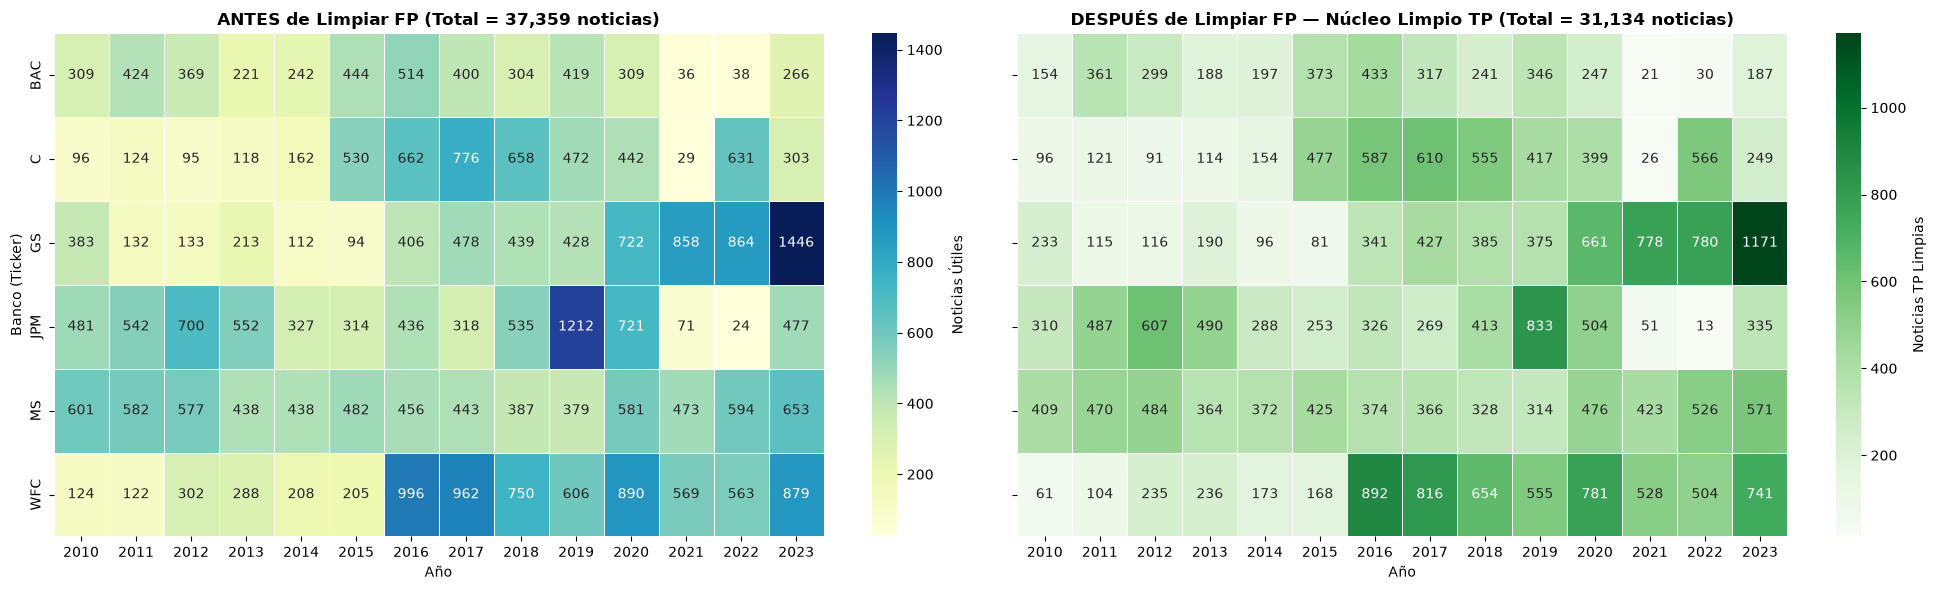

RESUMEN DE COBERTURA ANUAL POST-LIMPIEZA DE FALSOS POSITIVOS:


,Total_Antes,Total_Despues_TP,Años_con_0_Noticias,Minimo_Anual_TP,Año_del_Minimo
ticker,,,,,
BAC,4295,3394,0,21,2021
C,5098,4462,0,26,2021
GS,6708,5749,0,81,2015
JPM,6710,5179,0,13,2022
MS,7084,5902,0,314,2019
WFC,7464,6448,0,61,2010


In [5]:
df_tp = df_util[~df_util["es_fp_detectado"]].copy()
years_range = list(range(2010, 2024))

piv_antes = (
    df_util.groupby(["ticker", "year"]).size().unstack(fill_value=0)
    .reindex(columns=years_range, fill_value=0)
)
piv_despues = (
    df_tp.groupby(["ticker", "year"]).size().unstack(fill_value=0)
    .reindex(columns=years_range, fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharey=True)

sns.heatmap(
    piv_antes, annot=True, fmt="d", cmap="YlGnBu", linewidths=0.5,
    ax=axes[0], cbar_kws={"label": "Noticias Útiles"}
)
axes[0].set_title(f"ANTES de Limpiar FP (Total = {len(df_util):,} noticias)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Banco (Ticker)")

sns.heatmap(
    piv_despues, annot=True, fmt="d", cmap="Greens", linewidths=0.5,
    ax=axes[1], cbar_kws={"label": "Noticias TP Limpias"}
)
axes[1].set_title(f"DESPUÉS de Limpiar FP — Núcleo Limpio TP (Total = {len(df_tp):,} noticias)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Verificar mínimo anual por banco tras la limpieza
resumen_minimos = pd.DataFrame({
    "Total_Antes": piv_antes.sum(axis=1),
    "Total_Despues_TP": piv_despues.sum(axis=1),
    "Años_con_0_Noticias": (piv_despues == 0).sum(axis=1),
    "Minimo_Anual_TP": piv_despues.min(axis=1),
    "Año_del_Minimo": piv_despues.idxmin(axis=1),
})
print("RESUMEN DE COBERTURA ANUAL POST-LIMPIEZA DE FALSOS POSITIVOS:")
display(resumen_minimos)

---
## 6. Validación Final de Pureza: Muestra Aleatoria de 5 Noticias por Banco sobre el Núcleo Limpio (`TP`)

Finalmente, extraemos **5 noticias aleatorias por cada banco (`N = 30`)** tomadas exclusivamente del subconjunto depurado (`TP: Núcleo Limpio`) para verificar el salto de calidad y precisión frente a la muestra original sin depurar.

In [6]:
muestra_tp_limpia = (
    df_tp.groupby("ticker", group_keys=False)
    .sample(n=5, random_state=42)[cols_vista]
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)

print("=" * 105)
print("✔ MUESTRA ALEATORIA DE 5 NOTICIAS POR BANCO SOBRE EL NÚCLEO LIMPIO (POST-FILTRADO DE FP)")
print("=" * 105)
display(muestra_tp_limpia)

✔ MUESTRA ALEATORIA DE 5 NOTICIAS POR BANCO SOBRE EL NÚCLEO LIMPIO (POST-FILTRADO DE FP)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2011-07-07 20:18:00,BAC,earnings,43.50,TP: Núcleo Limpio (Señal Válida),"U.S. stocks close higher on tech, bank gains","47 points, or 0.7%, at 12,719.49. Intel Corp. and Cisco Systems Inc. shares both closed up more than 2%, and shares of J.P. Morgan Chase & Co. and Bank of America Corp. climbed 1.9% and 1.7%, respectively. The S&P 500 Index closed up 14 points, or 1.1%, at 1,353.22, and the Nasdaq Composite Index increased by 38.64 points, or 1.4%, to close at 2,872.66."
1,2011-10-27 20:40:00,BAC,m&a,60.15,TP: Núcleo Limpio (Señal Válida),"Morgan Stanley, Bank of America power financials","The sector take a cue from Europe, rallying as investors cheer an apparent agreement among euro-zone leaders to bail out Greece and have the region’s banks recapitalized. Morgan Stanley proves a big winner."
2,2011-11-28 21:56:00,BAC,macro,47.82,TP: Núcleo Limpio (Señal Válida),Financial stocks pace broader market,U.S. financial stocks pace the broader market on strong holiday spending from consumers and reports that politicians are close to a decision on how to support the European economy.
3,2013-11-19 05:01:00,BAC,m&a,51.48,TP: Núcleo Limpio (Señal Válida),The Best Bank Stocks,Analyst Matt Olney has a track record of picking winners for Barron's; here are his nine best values in the banking sector.
4,2017-04-17 00:00:00,BAC,earnings,57.89,TP: Núcleo Limpio (Señal Válida),"Earnings: Another Financial Roundup With BAC, GS, and MS",(Titular directo sin cuerpo)
5,2017-12-04 00:00:00,C,earnings,39.86,TP: Núcleo Limpio (Señal Válida),NYSE Indexes Hold Early Gains But Chips Sink Nasdaq,"Breakouts in the bank sector Monday included Citigroup ( C ), which cleared a 76.24 buy point in strong volume. Bank of New York Mellon ( BK ) was trying to cross above a 55.39 buy point."
6,2018-04-13 13:46:00,C,earnings,40.67,TP: Núcleo Limpio (Señal Válida),"Financial Stocks Pare Most Pre-Market Gains: JP Morgan, Citi, Wells Fargo Traded Up Between 1-2%, Now Flirting With Unch",(Titular directo sin cuerpo)
7,2019-03-11 00:00:00,C,legal,49.61,TP: Núcleo Limpio (Señal Válida),"UBS Group, Standard Chartered to Settle IPO Misconduct Case","UBS Group's case under appeal is among the series of similar actions undertaken by the SFC to tighten oversight. In 2018, the regulator fined Citigroup C and China Construction Bank International, an investment bank wholly owned by China Construction Bank Corporation CICHY , over similar allegations."
8,2022-04-18 00:00:00,C,macro,52.99,TP: Núcleo Limpio (Señal Válida),US STOCKS-Wall Street set to open lower as yields continue to rise,"Market response to first-quarter bank earnings have been mixed as JPMorgan Chase & Co JPM.N, Goldman Sachs Group Inc GS.N and Citigroup Inc C.N combined put aside $3.36 billion in credit loss reserves due to risks from the Ukraine war and rising inflation."
9,2022-09-09 00:00:00,C,m&a,51.40,TP: Núcleo Limpio (Señal Válida),Big banks to rake in record profits from commodities this year,"Banks such as Goldman Sachs GS.N, Citi C.N and Macquarie MQG.AX have benefitted from massive volatility and supply chain disruption in commodities markets that began in 2020 and increased this year with Russia's invasion of Ukraine."
